# Assignment test cases: estimator comparison

Run all cells to compare **straight**, **turning**, and **abrupt-maneuver** scenarios.
Results appear inline for every case. Defaults compare the particle filter,
EKF with innovation monitoring, and EKF with rejection enabled, using sensor seed 42.
The rejection variant is an experiment, not an assumed improvement.

Edit **CASE_RUNS** to add other methods or saved runs; edit **PLOT_CASES** to select
which cases produce plots. The notebook reads saved main CSVs and their neighboring
`.summary.json` files. Ground truth and timestamps must match within each case.

In [1]:
%matplotlib inline
import csv
import json
from html import escape
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "controls" / "main.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside ControlsProject.")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

No event loop hook running.


## Select assignment cases and methods

The nine example output pairs have been generated under `output/assignment/`.
All use the supplied assignment CSVs, the same sensor seed (42), controller,
recovery rule, and nominal noise settings. Add a method to `METHOD_FILES` when
its outputs use the same filename convention, or edit `CASE_RUNS` directly.

`monitor` records large normalized innovations without changing the EKF updates.
`reject` skips those corrections and retains the prediction/covariance. Neither
mode changes the motion model. Rejection alone can worsen recovery when a prior
estimate is already wrong; compare the results instead of assuming a benefit.

In [2]:
CASE_FILES = {
    "Straight": "straight",
    "Turning": "turning",
    "Abrupt maneuver": "abrupt_maneuver",
}
METHOD_FILES = {
    "Particle filter": "particle",
    "EKF (monitor)": "ekf_monitor",
    "EKF (reject)": "ekf_reject",
}
CASE_RUNS = {
    title: {label: f"output/assignment/{case}_{method}.csv" for label, method in METHOD_FILES.items()}
    for title, case in CASE_FILES.items()
}
PLOT_CASES = list(CASE_RUNS)  # e.g. ["Abrupt maneuver"] for fewer plots.
# Choose the summary rows displayed for each case.
METRICS = [
    ("Position RMSE (m)", "positionRMSE"),
    ("Max position error (m)", "maxError"),
    ("Mean uncertainty (m)", "meanPositionUncertainty"),
    ("Max uncertainty (m)", "maxPositionUncertainty"),
    ("Uncertainty time coverage (%)", "uncertaintyTimeCoverage"),
    ("Valid-read time (%)", "validTimeRate"),
    ("Valid measurement attempts (%)", "validRate"),
    ("Mean reader/tag separation (m)", "meanTrackingDistance"),
    ("Max reader/tag separation (m)", "maxTrackingDistance"),
    ("Time at speed limit (%)", "speedLimitUsage"),
    ("Time at turn-rate limit (%)", "turnRateLimitUsage"),
    ("Mean NIS (before gating)", "meanNIS"),
    ("Max NIS (before gating)", "maxNIS"),
    ("Flagged innovations", "innovationOutliers"),
    ("Rejected measurements", "measurementUpdatesRejected"),
]

In [3]:
def show_table(headers, rows):
    header = "".join(f"<th>{escape(str(v))}</th>" for v in headers)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(v))}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))

def fmt(value):
    if value is None or (isinstance(value, (float, int)) and not np.isfinite(value)):
        return "N/A"
    return f"{value:.3f}" if isinstance(value, (float, int)) else str(value)

def load_run(label, filename):
    path = ROOT / filename
    summary_path = path.with_suffix(".summary.json")
    with path.open(newline="", encoding="utf-8-sig") as stream:
        reader = csv.DictReader(stream)
        rows = list(reader)
        headers = reader.fieldnames or []
    required = {"time", "true_x", "true_y", "true_vx", "true_vy", "est_x", "est_y",
                "reader_x", "reader_y", "estimation_error", "tracking_distance", "valid"}
    if not required.issubset(headers):
        raise ValueError(f"{label}: use a main simulation CSV; missing {sorted(required - set(headers))}")
    if not rows:
        raise ValueError(f"{label}: CSV contains no samples")
    def number(value):
        if value in (None, ""):
            return np.nan
        return float({"True": "1", "False": "0"}.get(value, value))
    text_columns = {"event", "innovation_gate_mode", "measurement_rejection_reason"}
    data = {key: np.array([number(row.get(key)) for row in rows])
            for key in headers if key not in text_columns}
    for key in text_columns:
        data[key] = np.array([row.get(key, "") for row in rows])
    time = data["time"]
    if not np.all(np.isfinite(time)) or np.any(np.diff(time) <= 0):
        raise ValueError(f"{label}: timestamps must be finite and strictly increasing")
    for key in ("true_x", "true_y", "true_vx", "true_vy"):
        if not np.all(np.isfinite(data[key])):
            raise ValueError(f"{label}: non-finite ground truth in {key}")
    if not summary_path.exists():
        raise FileNotFoundError(f"{label}: missing {summary_path.name}; rerun with the current logger")
    summary = json.loads(summary_path.read_text())
    error = np.hypot(data["est_x"] - data["true_x"], data["est_y"] - data["true_y"])
    finite = np.isfinite(error)
    rmse = np.sqrt(np.mean(error[finite] ** 2)) if finite.any() else None
    summary_rmse = summary.get("positionRMSE")
    rmse_matches = ((rmse is None and summary_rmse is None) or
                    (rmse is not None and summary_rmse is not None and np.isclose(rmse, summary_rmse)))
    if (summary.get("samples") != len(rows) or not rmse_matches or
            not np.isclose(summary.get("duration", np.nan), time[-1] - time[0])):
        raise ValueError(f"{label}: summary does not match CSV; regenerate the output pair")
    if not np.allclose(error, data["estimation_error"], equal_nan=True):
        raise ValueError(f"{label}: saved position errors do not match the trajectories")
    return {"label": label, "path": path, "data": data, "summary": summary}


def load_case(filenames):
    if not filenames:
        raise ValueError("Add at least one labeled output CSV per case")
    runs = [load_run(label, filename) for label, filename in filenames.items()]
    reference = runs[0]["data"]
    for run in runs[1:]:
        for key in ("time", "true_x", "true_y", "true_vx", "true_vy"):
            values = run["data"][key]
            if values.shape != reference[key].shape or not np.allclose(values, reference[key], rtol=1e-9, atol=1e-9):
                raise ValueError(f"{run['label']}: {key} differs; select outputs for the same ground-truth scenario")
    for index, run in enumerate(runs):
        run["color"] = plt.get_cmap("tab10" if len(runs) <= 10 else "tab20")(index % 20)
    return runs

if not CASE_RUNS:
    raise ValueError("Add at least one case to CASE_RUNS")
case_runs = {title: load_case(filenames) for title, filenames in CASE_RUNS.items()}
if not set(PLOT_CASES).issubset(case_runs):
    raise ValueError("PLOT_CASES contains an unknown case")

def series(run, key):
    return run["data"].get(key, np.full(len(run["data"]["time"]), np.nan))

def mark_events(axis, runs):
    events = {}
    for run in runs:
        for time, name in zip(run["data"]["time"], run["data"]["event"]):
            if name:
                events[(float(time), name)] = True
    for time, name in events:
        axis.axvline(time, color="0.5", linestyle=":", alpha=0.45)
        axis.text(time, 0.98, name, transform=axis.get_xaxis_transform(), fontsize=8,
                  rotation=90, va="top", ha="right", color="0.35")


show_table(["Case", "Run", "CSV", "Samples", "Duration (s)"],
           [[title, r["label"], r["path"].relative_to(ROOT) if r["path"].is_relative_to(ROOT) else r["path"],
             r["summary"]["samples"], fmt(r["summary"]["duration"])]
            for title, runs in case_runs.items() for r in runs])
print("Validated matching ground-truth paths and timestamps within each case.")

Validated matching ground-truth paths and timestamps within each case.


Case,Run,CSV,Samples,Duration (s)
Straight,Particle filter,output/assignment/straight_particle.csv,201,20.000
Straight,EKF (monitor),output/assignment/straight_ekf_monitor.csv,201,20.000
Straight,EKF (reject),output/assignment/straight_ekf_reject.csv,201,20.000
Turning,Particle filter,output/assignment/turning_particle.csv,201,20.000
Turning,EKF (monitor),output/assignment/turning_ekf_monitor.csv,201,20.000
Turning,EKF (reject),output/assignment/turning_ekf_reject.csv,201,20.000
Abrupt maneuver,Particle filter,output/assignment/abrupt_maneuver_particle.csv,201,20.000
Abrupt maneuver,EKF (monitor),output/assignment/abrupt_maneuver_ekf_monitor.csv,201,20.000
Abrupt maneuver,EKF (reject),output/assignment/abrupt_maneuver_ekf_reject.csv,201,20.000


## Summary metrics

Uncertainty is the reported `sqrt(cov_xx + cov_yy)`, not a guaranteed confidence
radius. Missing values stay **N/A**. Recovery is shown per event below so that
unrecovered events are not silently discarded from an average.

In [4]:
def metric_value(run, key):
    if key in {"meanNIS", "maxNIS", "innovationOutliers", "measurementUpdatesRejected"} and not run["summary"].get("innovationGateMode"):
        return None  # Not applicable to an estimator without innovation checks.
    return run["summary"].get(key)

for TITLE, runs in case_runs.items():
    display(Markdown(f"### {TITLE}"))
    rows = [[label, *[fmt(metric_value(r, key)) for r in runs]] for label, key in METRICS]
    rows.append(["Estimated samples", *[f"{r['summary']['estimatedSamples']} / {r['summary']['samples']}" for r in runs]])
    rows.append(["Recovery events confirmed / total", *[
        f"{sum(e['status'] == 'recovered' for e in r['summary'].get('recoveryEvents', []))} / {len(r['summary'].get('recoveryEvents', []))}"
        for r in runs]])
    show_table(["Metric", *[r["label"] for r in runs]], rows)
    show_table(["Run", "Speed limit (m/s)", "Turn limit (rad/s)", "Recovery error (m)", "Recovery hold (s)", "Gate mode", "NIS threshold"],
               [[r["label"], *[fmt(metric_value(r, key)) for key in
                 ("maxVelocity", "maxTurnRate", "recoveryThreshold", "recoveryHoldTime", "innovationGateMode", "innovationGateThreshold")]] for r in runs])
    rules = {(r["summary"].get("recoveryThreshold"), r["summary"].get("recoveryHoldTime")) for r in runs}
    if len(rules) > 1:
        display(Markdown("**Recovery rules differ between runs. Match them before comparing recovery times.**"))

<IPython.core.display.Markdown object>

Metric,Particle filter,EKF (monitor),EKF (reject)
Position RMSE (m),0.413,1.188,1.029
Max position error (m),1.059,3.460,4.075
Mean uncertainty (m),0.244,0.238,0.427
Max uncertainty (m),0.611,0.592,1.636
Uncertainty time coverage (%),100.000,100.000,100.000
Valid-read time (%),96.500,96.500,96.500
Valid measurement attempts (%),96.517,96.517,96.517
Mean reader/tag separation (m),0.546,0.538,0.573
Max reader/tag separation (m),2.828,2.828,2.828
Time at speed limit (%),0.000,0.000,0.000


Run,Speed limit (m/s),Turn limit (rad/s),Recovery error (m),Recovery hold (s),Gate mode,NIS threshold
Particle filter,2.000,1.500,0.500,1.000,N/A,N/A
EKF (monitor),2.000,1.500,0.500,1.000,monitor,9.210
EKF (reject),2.000,1.500,0.500,1.000,reject,9.210


<IPython.core.display.Markdown object>

Metric,Particle filter,EKF (monitor),EKF (reject)
Position RMSE (m),0.400,1.289,2.519
Max position error (m),1.056,3.870,7.137
Mean uncertainty (m),0.267,0.238,0.508
Max uncertainty (m),0.611,0.592,2.010
Uncertainty time coverage (%),100.000,100.000,100.000
Valid-read time (%),96.500,96.500,96.500
Valid measurement attempts (%),96.517,96.517,96.517
Mean reader/tag separation (m),0.564,0.514,1.028
Max reader/tag separation (m),2.828,2.828,4.474
Time at speed limit (%),0.000,0.000,0.000


Run,Speed limit (m/s),Turn limit (rad/s),Recovery error (m),Recovery hold (s),Gate mode,NIS threshold
Particle filter,2.000,1.500,0.500,1.000,N/A,N/A
EKF (monitor),2.000,1.500,0.500,1.000,monitor,9.210
EKF (reject),2.000,1.500,0.500,1.000,reject,9.210


<IPython.core.display.Markdown object>

Metric,Particle filter,EKF (monitor),EKF (reject)
Position RMSE (m),0.365,1.414,1.025
Max position error (m),0.946,4.505,3.042
Mean uncertainty (m),0.201,0.238,0.422
Max uncertainty (m),0.611,0.592,1.865
Uncertainty time coverage (%),100.000,100.000,100.000
Valid-read time (%),96.500,96.500,96.500
Valid measurement attempts (%),96.517,96.517,96.517
Mean reader/tag separation (m),0.604,0.557,1.143
Max reader/tag separation (m),2.828,2.828,2.828
Time at speed limit (%),0.000,0.000,0.000


Run,Speed limit (m/s),Turn limit (rad/s),Recovery error (m),Recovery hold (s),Gate mode,NIS threshold
Particle filter,2.000,1.500,0.500,1.000,N/A,N/A
EKF (monitor),2.000,1.500,0.500,1.000,monitor,9.210
EKF (reject),2.000,1.500,0.500,1.000,reject,9.210


## Trajectories

Solid colored lines are estimates; dashed lines are the corresponding reader paths.
These are closed-loop system comparisons: different estimates can produce different
reader paths and therefore different measurements, even with the same sensor seed.
A comparison of filtering alone would need a shared replayed measurement sequence.

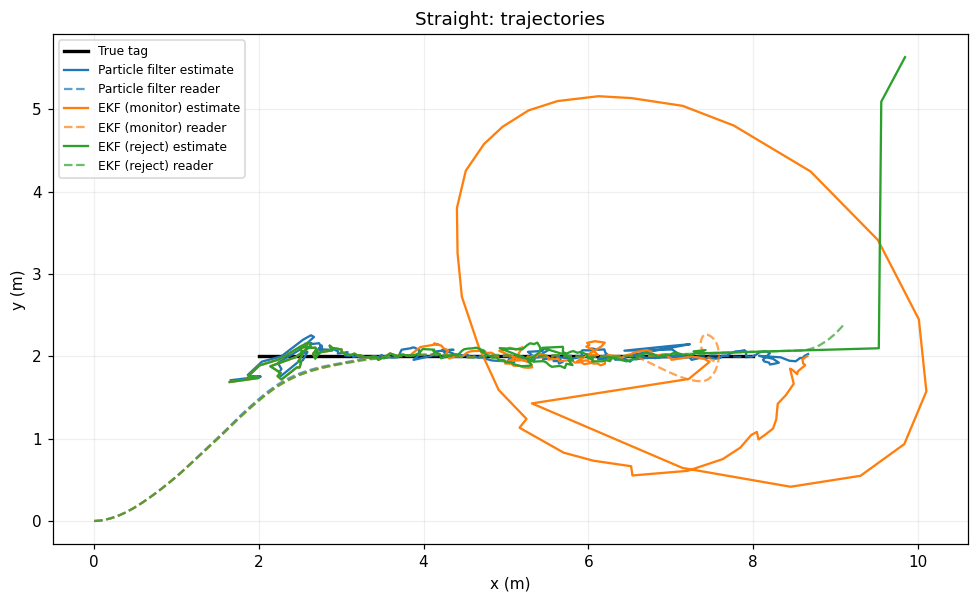

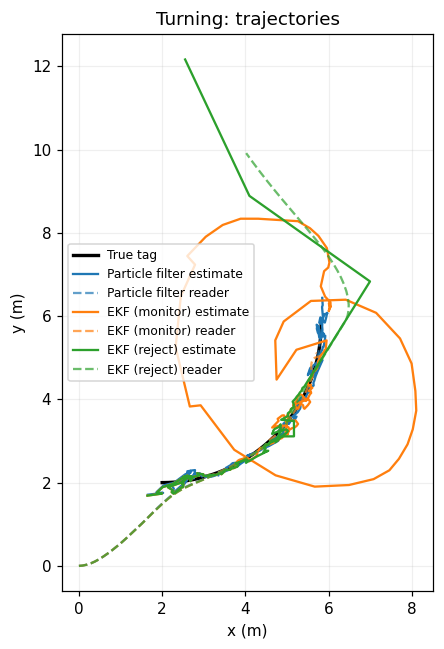

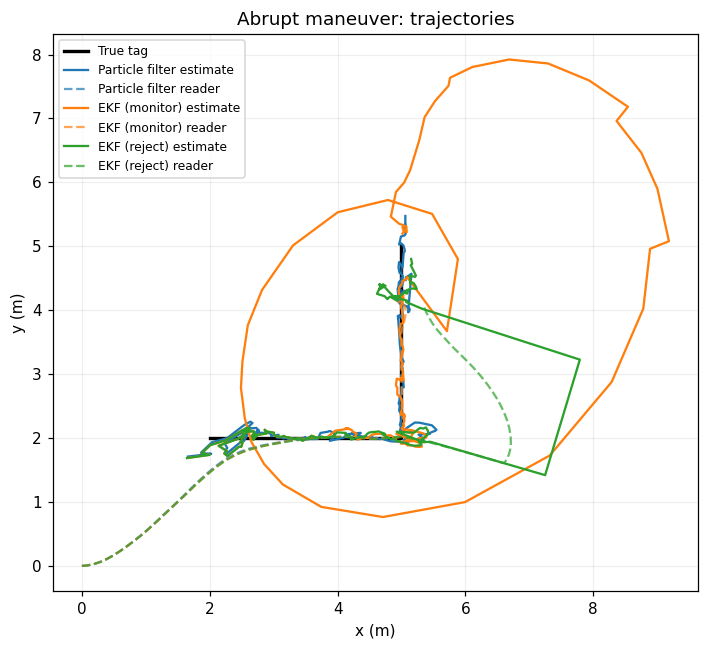

In [5]:
for TITLE in PLOT_CASES:
    runs = case_runs[TITLE]
    reference = runs[0]["data"]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(reference["true_x"], reference["true_y"], color="black", linewidth=2.2, label="True tag")
    for run in runs:
        d, color = run["data"], run["color"]
        ax.plot(d["est_x"], d["est_y"], color=color, label=f"{run['label']} estimate")
        ax.plot(d["reader_x"], d["reader_y"], "--", color=color, alpha=0.7, label=f"{run['label']} reader")
    ax.set(title=f"{TITLE}: trajectories", xlabel="x (m)", ylabel="y (m)", aspect="equal")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

## Estimation error, uncertainty, and separation

Compare actual position error against reported uncertainty to spot overconfidence.
Vertical dotted lines mark annotated scenario events, when present.

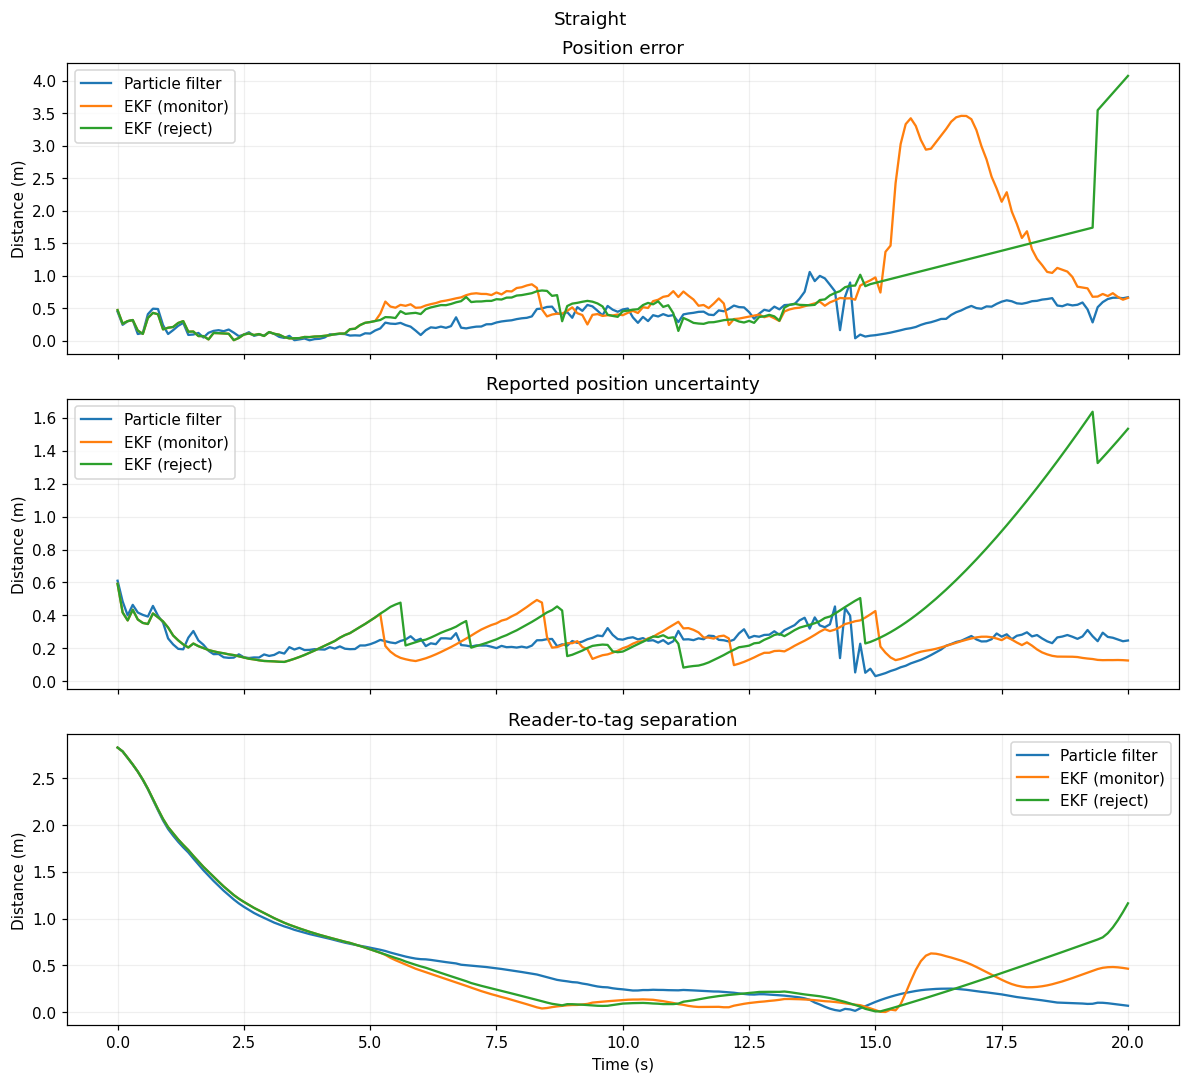

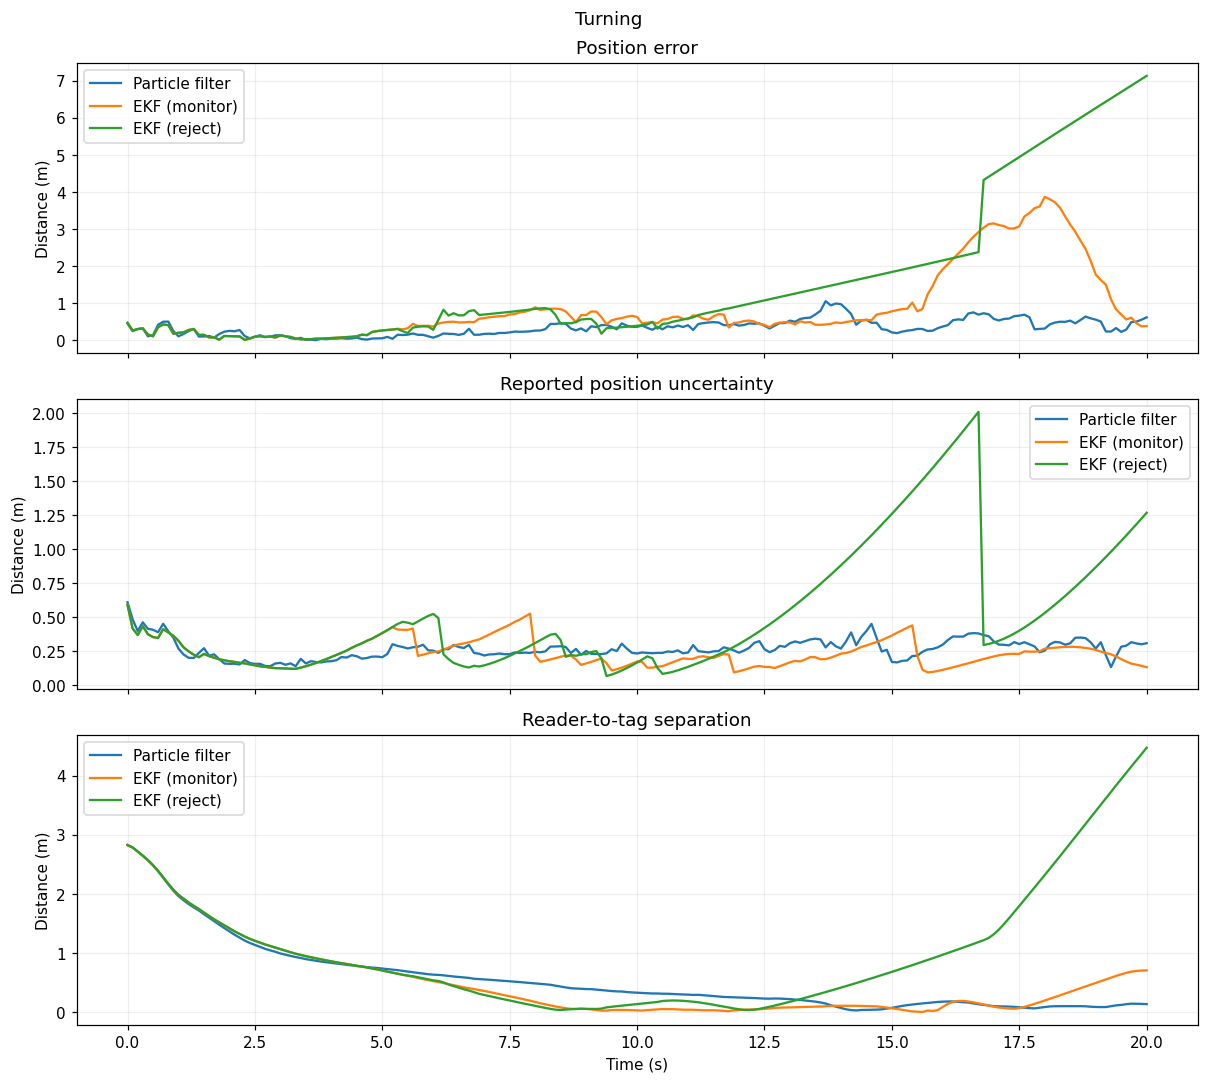

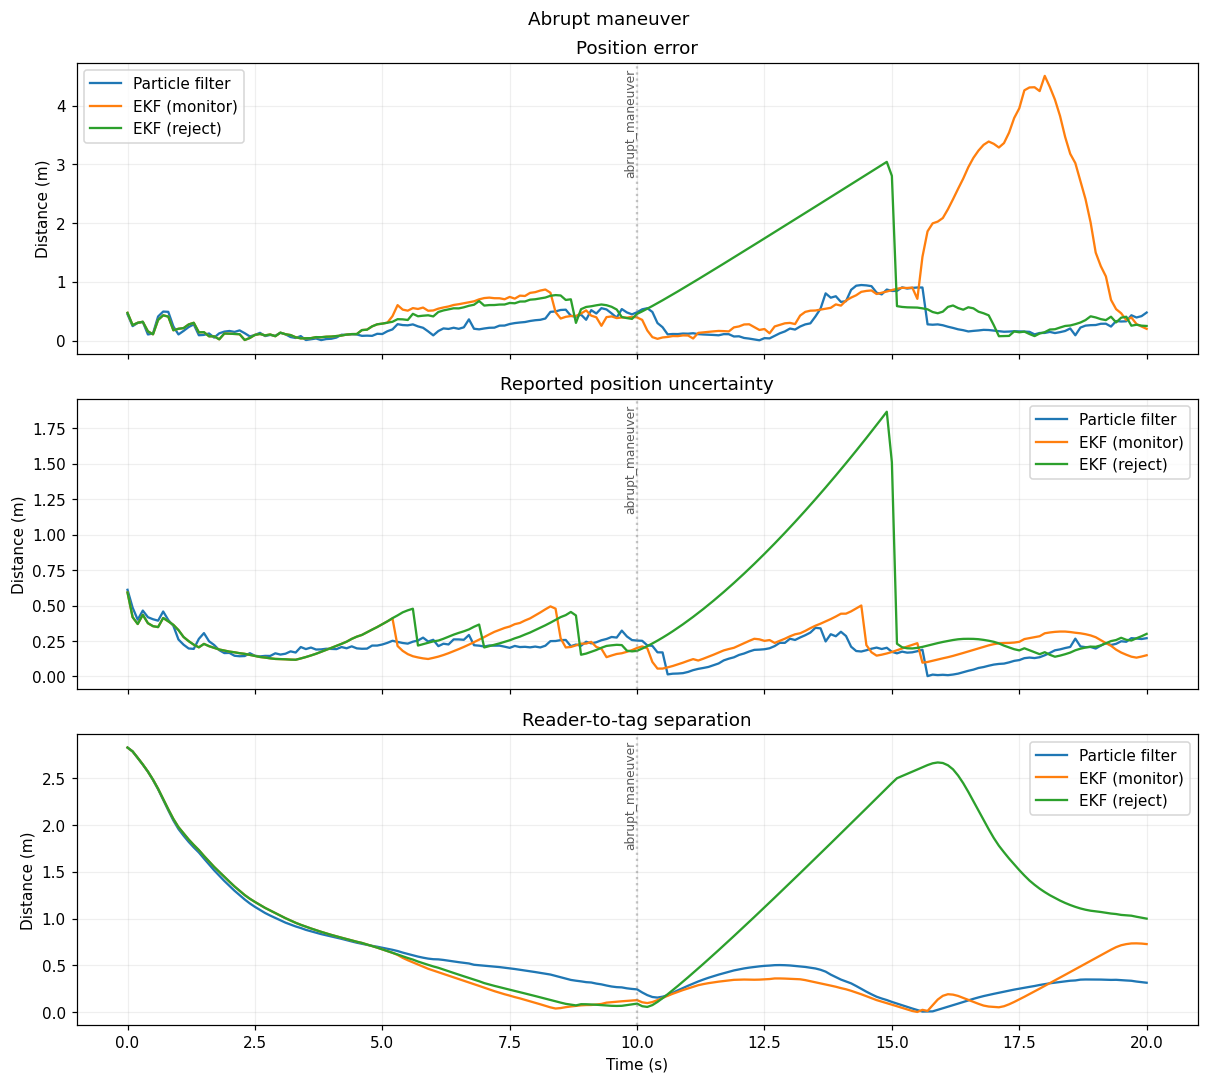

In [6]:
for TITLE in PLOT_CASES:
    runs = case_runs[TITLE]
    fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
    for run in runs:
        d, color = run["data"], run["color"]
        for ax, key in zip(axes, ("estimation_error", "position_uncertainty", "tracking_distance")):
            ax.plot(d["time"], series(run, key), color=color, label=run["label"])
    for ax, title in zip(axes, ("Position error", "Reported position uncertainty", "Reader-to-tag separation")):
        ax.set(title=title, ylabel="Distance (m)")
        ax.legend()
        mark_events(ax, runs)
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(TITLE)
    fig.tight_layout()
    plt.show()

## Read availability and measurements

A valid read remains available until the next scheduled attempt. Sensor attempts
that fail are separate from ticks with no sample due. RSSI and bearing plots show
only valid, fresh measurements; invalid RSSI zeros are not plotted as signal power.

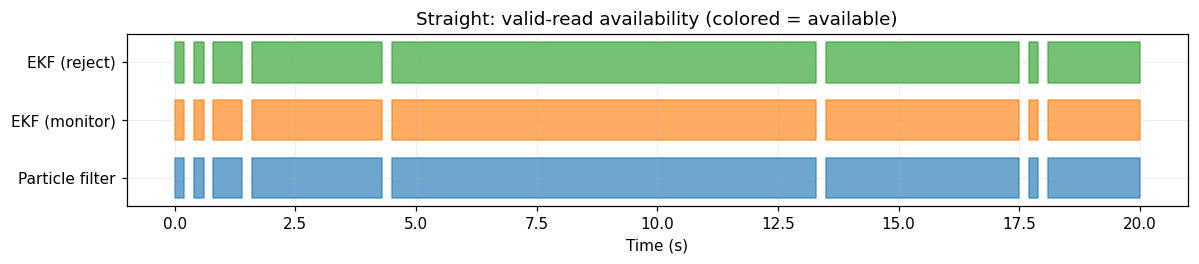

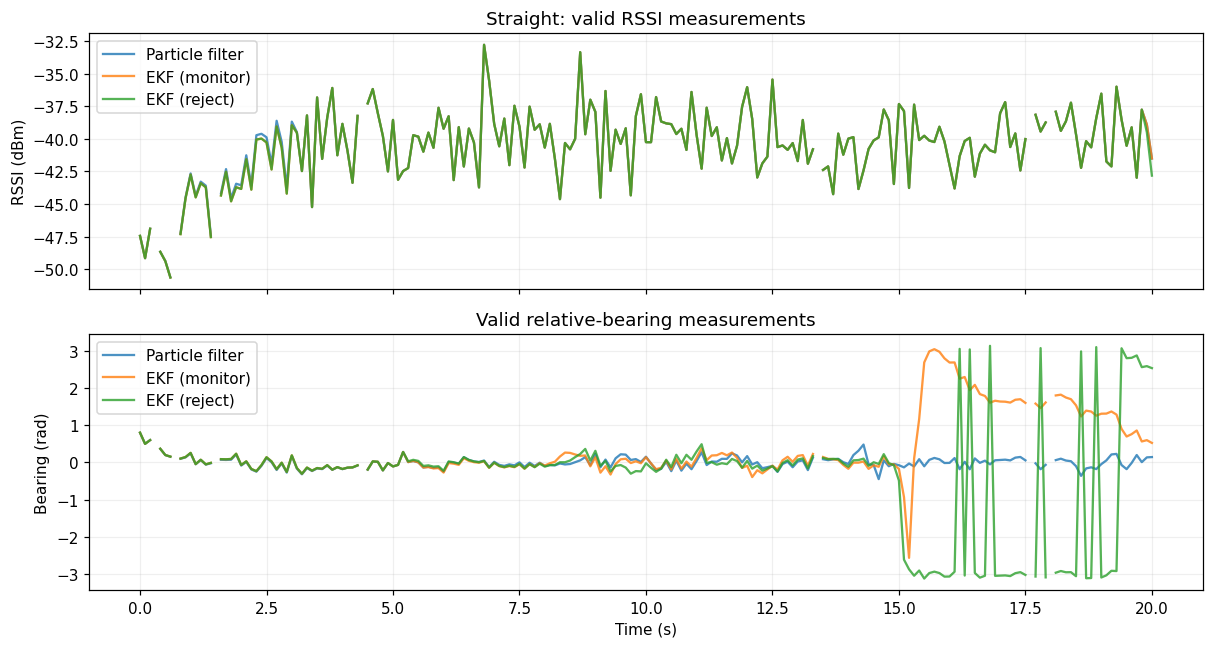

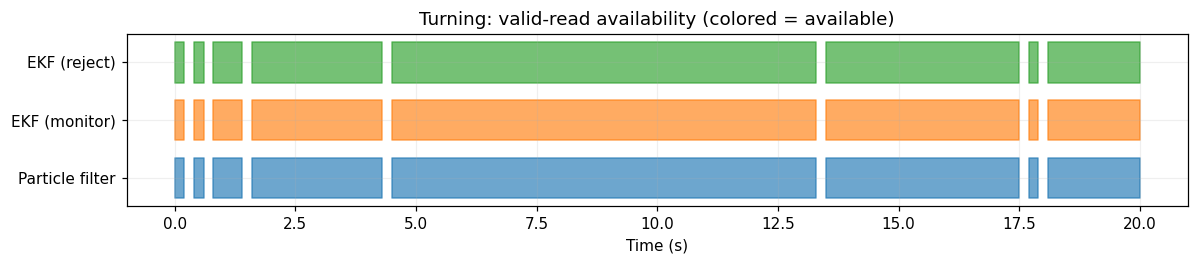

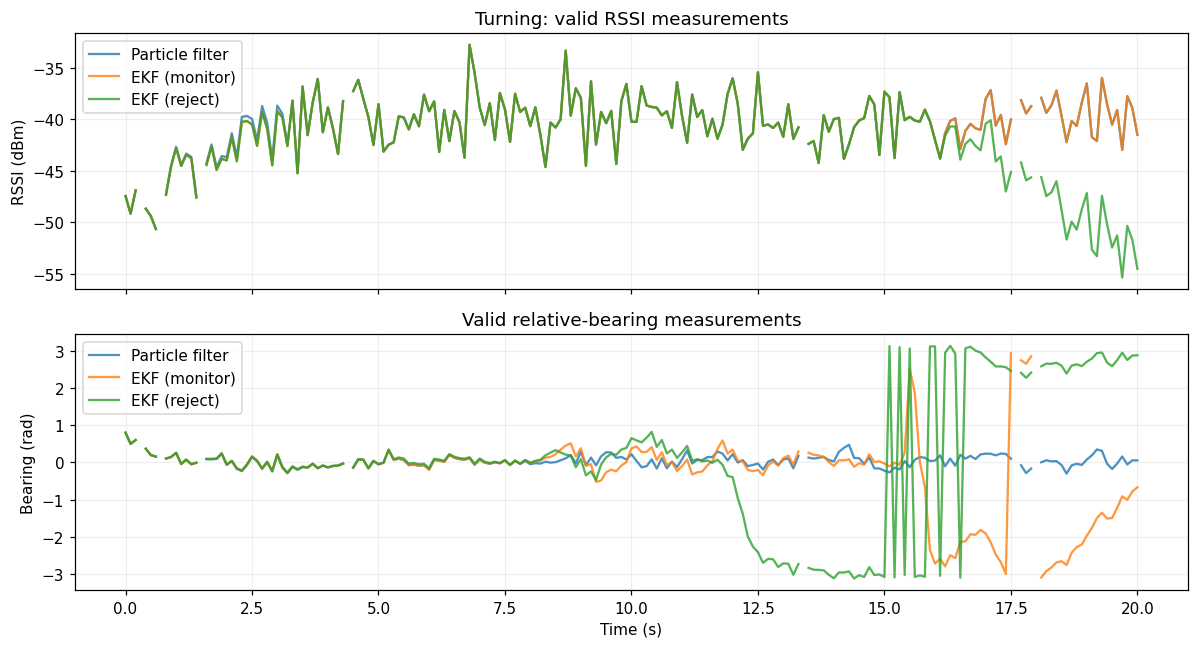

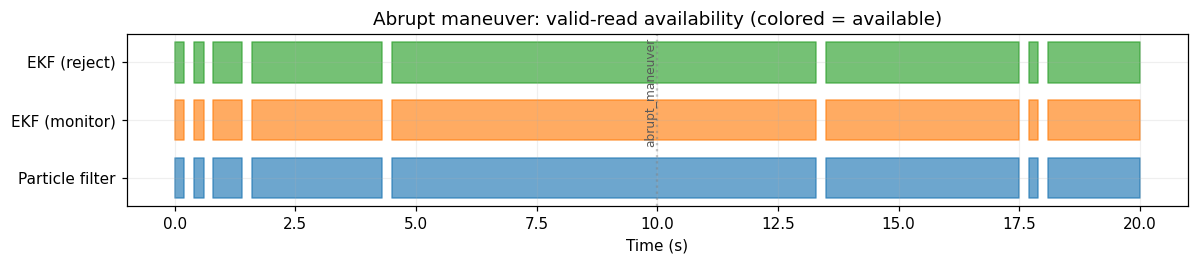

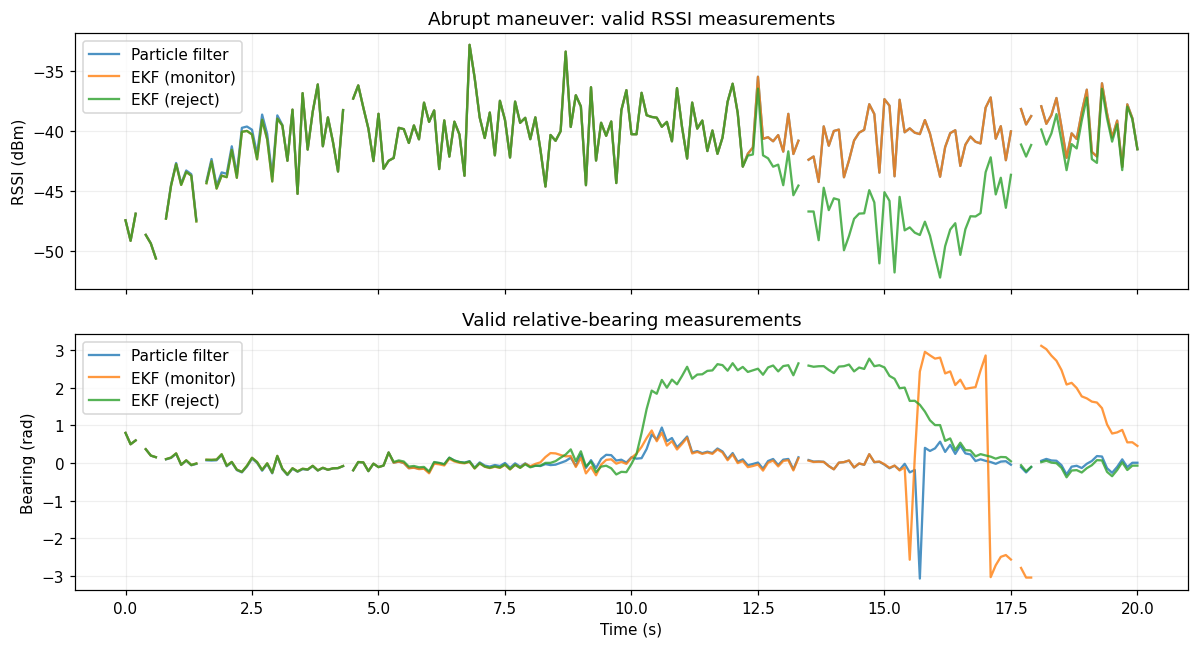

In [7]:
for TITLE in PLOT_CASES:
    runs = case_runs[TITLE]
    fig, ax = plt.subplots(figsize=(11, max(2.5, 0.65 * len(runs))))
    for index, run in enumerate(runs):
        available = []
        valid = False
        for due, reading in zip(series(run, "measurement_due"), series(run, "valid")):
            if due == 1:
                valid = reading == 1
            available.append(valid)
        time = run["data"]["time"]
        ax.fill_between(time, index, index + 0.7, where=available, step="post", color=run["color"], alpha=0.65)
    ax.set_yticks(np.arange(len(runs)) + 0.35, [r["label"] for r in runs])
    ax.set(title=f"{TITLE}: valid-read availability (colored = available)", xlabel="Time (s)")
    mark_events(ax, runs)
    fig.tight_layout()
    plt.show()

    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    for run in runs:
        valid = (series(run, "valid") == 1) & (series(run, "measurement_due") == 1)
        for ax, key in zip(axes, ("rssi", "bearing")):
            ax.plot(run["data"]["time"], np.where(valid, series(run, key), np.nan),
                    color=run["color"], alpha=0.8, label=run["label"])
    axes[0].set(title=f"{TITLE}: valid RSSI measurements", ylabel="RSSI (dBm)")
    axes[1].set(title="Valid relative-bearing measurements", ylabel="Bearing (rad)", xlabel="Time (s)")
    for ax in axes:
        ax.legend()
    fig.tight_layout()
    plt.show()

## Actuator commands and actual reader motion

Solid lines are commands; dashed lines are logged reader values. Dotted horizontal
lines show the configured limits. Speed and turn-rate usage percentages are in the
summary table. The current kinematic plant applies commands over the next interval.

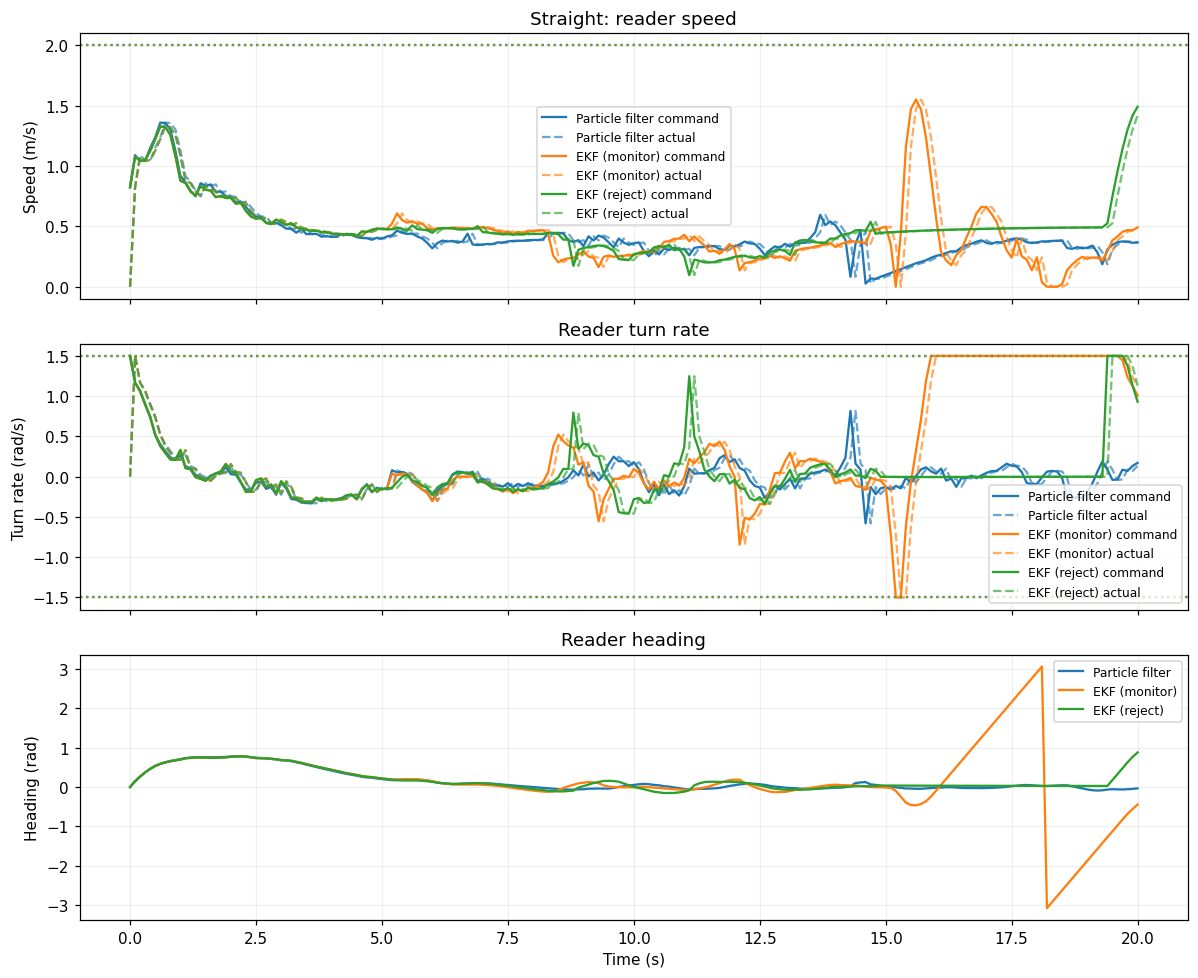

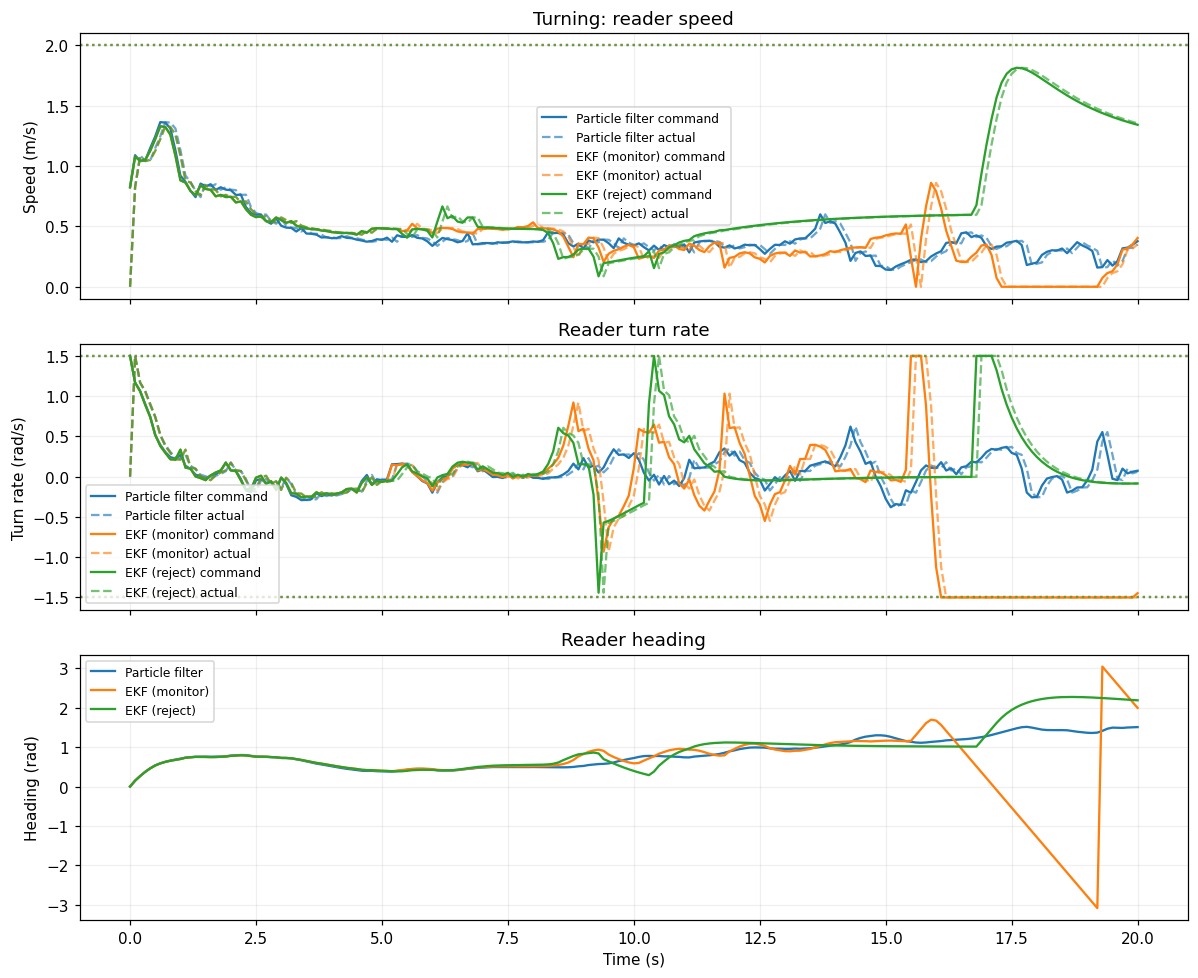

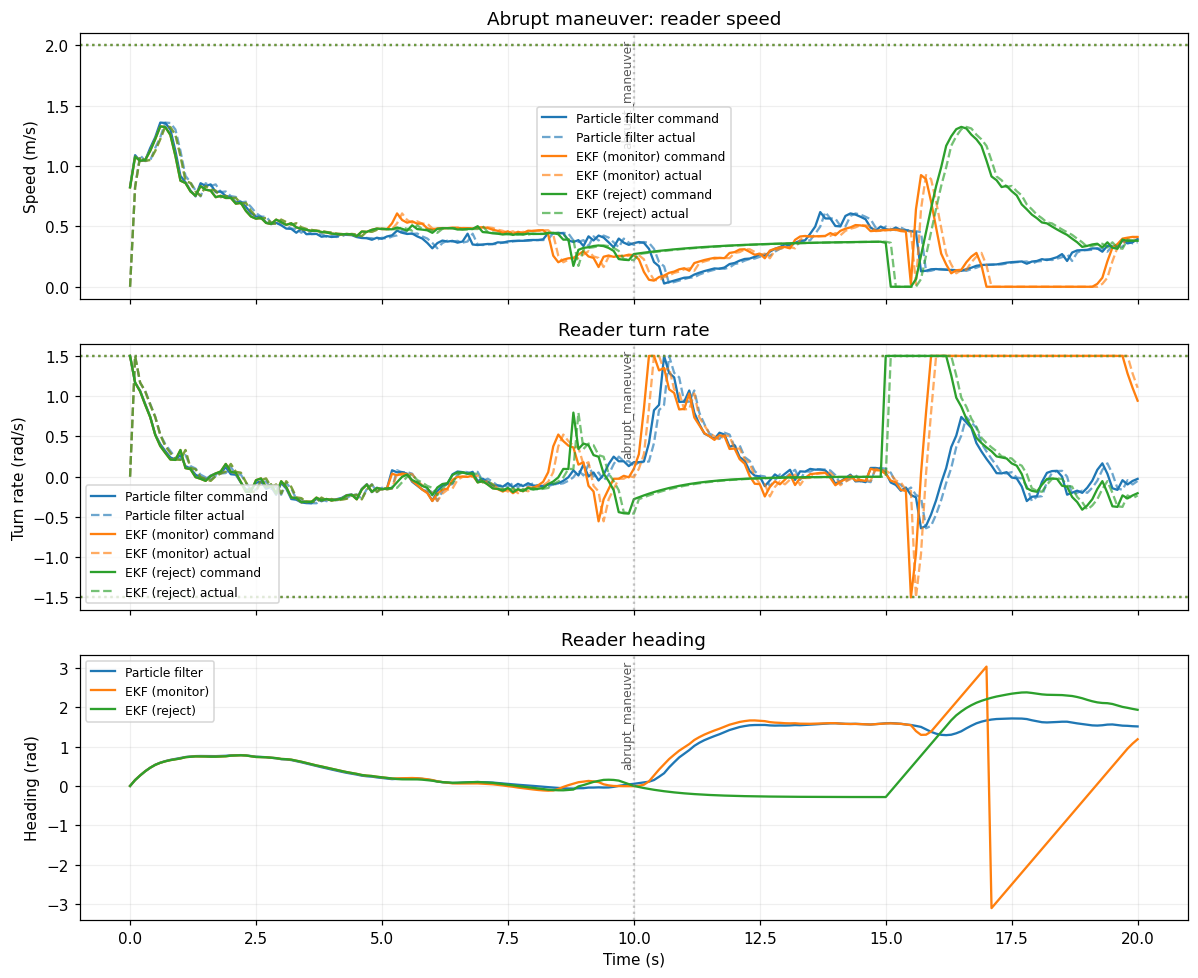

In [8]:
for TITLE in PLOT_CASES:
    runs = case_runs[TITLE]
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    for run in runs:
        d, color, summary = run["data"], run["color"], run["summary"]
        for ax, command, actual, limit_key in zip(axes[:2],
                ("command_velocity", "command_turnRate"), ("velocity", "turnSpeed"), ("maxVelocity", "maxTurnRate")):
            ax.plot(d["time"], series(run, command), color=color, label=f"{run['label']} command")
            ax.plot(d["time"], series(run, actual), "--", color=color, alpha=0.65, label=f"{run['label']} actual")
            limit = summary.get(limit_key)
            if limit is not None:
                ax.axhline(limit, color=color, linestyle=":", alpha=0.6)
                if command == "command_turnRate":
                    ax.axhline(-limit, color=color, linestyle=":", alpha=0.6)
    axes[0].set(title=f"{TITLE}: reader speed", ylabel="Speed (m/s)")
    axes[1].set(title="Reader turn rate", ylabel="Turn rate (rad/s)")
    for run in runs:
        axes[2].plot(run["data"]["time"], series(run, "heading"), color=run["color"], label=run["label"])
    axes[2].set(title="Reader heading", ylabel="Heading (rad)", xlabel="Time (s)")
    for ax in axes:
        ax.legend(fontsize=8)
        mark_events(ax, runs)
    fig.tight_layout()
    plt.show()

## Normalized innovations and rejected updates

NIS compares RSSI/bearing residuals against their predicted covariance **before**
any gate decision. The nominal 99% threshold is 9.21034 for two measurement
components under a correctly specified local Gaussian model. Large NIS flags an
inconsistent prior/measurement pair, not necessarily a bad sensor reading.
Monitoring flags but accepts; rejection skips the entire correction and preserves
predicted covariance. Missing/invalid readings and bootstrap initialization have
no NIS test. Raw sensor validity is distinct from measurement acceptance.

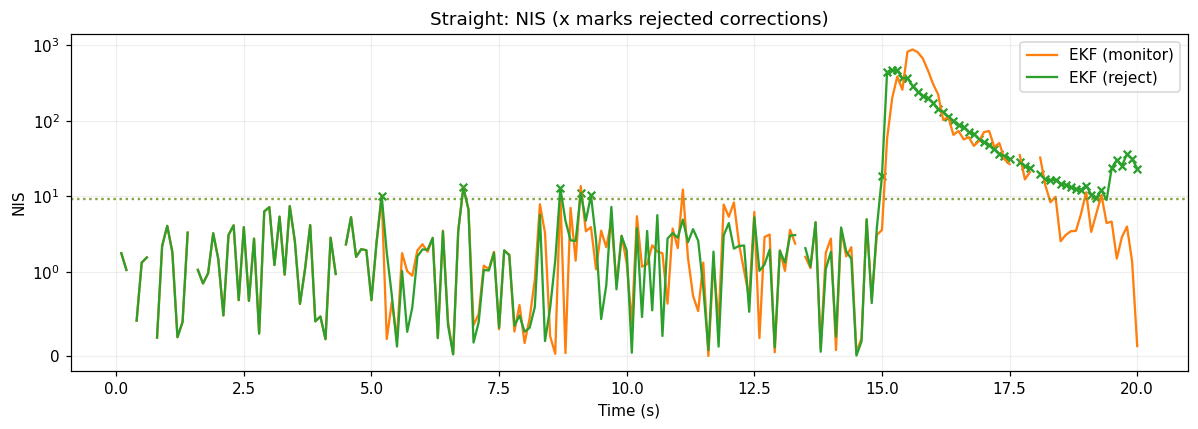

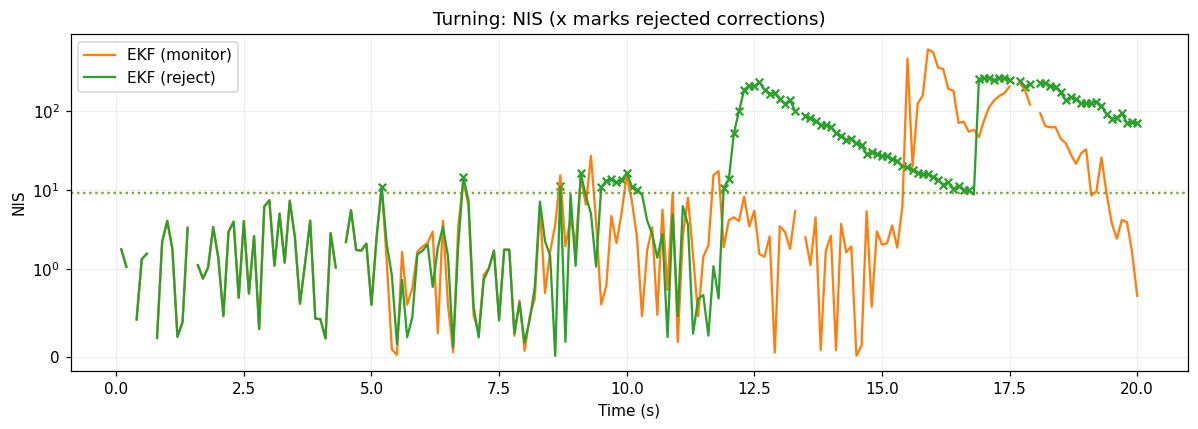

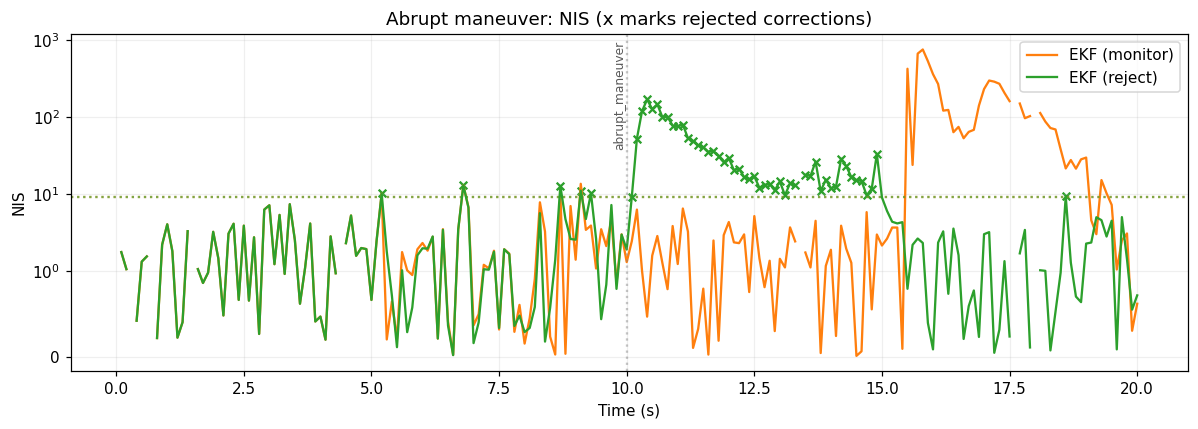

In [9]:
for TITLE in PLOT_CASES:
    runs = case_runs[TITLE]
    fig, ax = plt.subplots(figsize=(11, 4))
    checked = False
    for run in runs:
        time = run["data"]["time"]
        nis = series(run, "normalized_innovation_squared")
        if not np.isfinite(nis).any():
            continue
        checked = True
        ax.plot(time, nis, color=run["color"], label=run["label"])
        threshold = run["summary"].get("innovationGateThreshold")
        if threshold is not None:
            ax.axhline(threshold, color=run["color"], linestyle=":", alpha=0.6)
        rejected = (series(run, "measurement_accepted") == 0) & np.isfinite(nis)
        ax.scatter(time[rejected], nis[rejected], marker="x", color=run["color"], s=25)
    if checked:
        ax.set_yscale("symlog", linthresh=1)
        ax.legend()
    else:
        ax.text(0.5, 0.5, "No innovation diagnostics recorded", transform=ax.transAxes, ha="center")
    ax.set(title=f"{TITLE}: NIS (x marks rejected corrections)", xlabel="Time (s)", ylabel="NIS")
    mark_events(ax, runs)
    fig.tight_layout()
    plt.show()

## Recovery events

Recovery time includes the configured confirmation hold. Dropout clocks start at
first valid reacquisition; an explicit maneuver clock starts at its CSV event time.
**Interrupted**, **ongoing**, and **not recovered** events retain N/A recovery time.
The assignment's numerical acceptance thresholds remain your design choices.

In [10]:
rows = []
for TITLE, runs in case_runs.items():
    for run in runs:
        for event in run["summary"].get("recoveryEvents", []):
            rows.append([TITLE, run["label"], event["event"], fmt(event["start"]), fmt(event["end"]),
                         event["status"], fmt(event["recoveryTime"]), fmt(event["recoveredAt"])])
if rows:
    show_table(["Case", "Run", "Event", "Start (s)", "End (s)", "Status", "Recovery (s)", "Confirmed at (s)"], rows)
else:
    print("No dropout or annotated disturbance events were recorded.")

Case,Run,Event,Start (s),End (s),Status,Recovery (s),Confirmed at (s)
Straight,Particle filter,dropout,0.300,0.400,interrupted,N/A,N/A
Straight,Particle filter,dropout,0.700,0.800,interrupted,N/A,N/A
Straight,Particle filter,dropout,1.500,1.600,recovered,1.000,2.600
Straight,Particle filter,dropout,4.400,4.500,recovered,1.000,5.500
Straight,Particle filter,dropout,13.400,13.500,recovered,2.100,15.600
Straight,Particle filter,dropout,17.600,17.700,interrupted,N/A,N/A
Straight,Particle filter,dropout,18.000,18.100,not_recovered,N/A,N/A
Straight,EKF (monitor),dropout,0.300,0.400,interrupted,N/A,N/A
Straight,EKF (monitor),dropout,0.700,0.800,interrupted,N/A,N/A
Straight,EKF (monitor),dropout,1.500,1.600,recovered,1.000,2.600


These tables and plots compare saved runs; they do not establish statistical superiority
from one seed. For that, repeat matched scenarios over several seeds and summarize
across runs. Execution time, parameter-learning convergence, and accuracy of a learned
noise distribution are not recorded by the current simulator and cannot be inferred
from these files. Particle count and sensor settings should be documented with your runs.